# Food Delivery Analytics with SQL

**Business context:** A food-delivery startup operating in 6 cities wants answers to growth, operations and retention questions.
All analysis is done in **SQL (SQLite)** - Python is only used to run the queries and draw charts.

| Table | Rows | Description |
|---|---|---|
| `customers` | 6,000 | signup date, city, acquisition channel |
| `restaurants` | 220 | city, cuisine, rating, cloud-kitchen flag |
| `orders` | ~22k | timestamp, value, discount, fee, status, delivery minutes |

```
customers 1 ──< orders >── 1 restaurants
```
Each query lives in its own file under [`/sql`](../sql) so it can be reviewed, reused and versioned like real analytics code.

In [1]:
import sqlite3, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 200)
con = sqlite3.connect("../data/food_delivery.db")
IMG = "../images/"
def run(name):
    sql = open(f"../sql/{name}.sql").read()
    return pd.read_sql(sql, con)
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name.tolist())
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

['customers', 'restaurants', 'orders']


,order_id,order_ts,customer_id,restaurant_id,order_value,discount_amount,delivery_fee,payment_mode,status,delivery_minutes
0,10001,2025-01-01 14:11:00,4821,104,989.0,198.0,39.0,Card,Delivered,45.0
1,10002,2025-01-01 16:06:00,4719,155,1220.0,0.0,29.0,Wallet,Delivered,31.0
2,10003,2025-01-02 12:06:00,3057,155,409.0,0.0,39.0,UPI,Delivered,37.0
3,10004,2025-01-02 13:50:00,5813,171,1685.0,0.0,19.0,UPI,Delivered,39.0
4,10005,2025-01-02 14:56:00,3057,143,879.0,88.0,0.0,UPI,Delivered,38.0


## 1. Growth: monthly GMV, orders and cancellations
`sql/01_monthly_kpis.sql` - uses a CTE, conditional aggregation and `LAG()` for month-over-month growth.

,month,total_orders,delivered_orders,cancel_rate_pct,net_gmv,aov,gmv_mom_growth_pct,cumulative_gmv
0,2025-01,544,502,7.17,342968.0,725.1,NaN,342968.0
1,2025-02,895,819,7.15,550733.0,705.6,60.6,893701.0
2,2025-03,1168,1066,7.11,684319.0,682.7,24.3,1578020.0
3,2025-04,1403,1290,6.70,854178.0,698.9,24.8,2432198.0
4,2025-05,1672,1542,6.52,1024430.0,700.0,19.9,3456628.0
5,2025-06,1839,1684,7.34,1134980.0,709.3,10.8,4591608.0
6,2025-07,2167,1962,8.81,1264289.0,682.6,11.4,5855897.0
7,2025-08,2186,1992,7.87,1317056.0,695.4,4.2,7172953.0
8,2025-09,2249,2069,6.49,1377178.0,703.4,4.6,8550131.0
9,2025-10,2541,2363,5.90,1578198.0,704.0,14.6,10128329.0


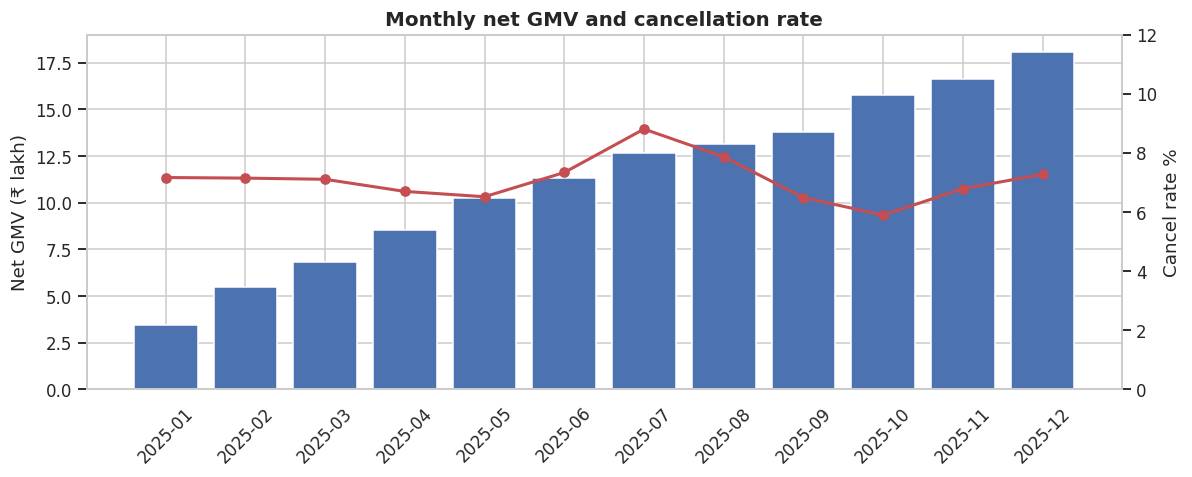

In [2]:
kpi = run("01_monthly_kpis"); display(kpi)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(kpi.month, kpi.net_gmv/1e5, color="#4c72b0"); ax.set_ylabel("Net GMV (₹ lakh)"); ax.set_title("Monthly net GMV and cancellation rate")
ax2 = ax.twinx(); ax2.plot(kpi.month, kpi.cancel_rate_pct, color="#c44e52", marker="o", lw=2); ax2.set_ylabel("Cancel rate %"); ax2.set_ylim(0, 12); ax2.grid(False)
plt.setp(ax.get_xticklabels(), rotation=45); plt.tight_layout(); plt.savefig(IMG + "01_monthly_gmv.png"); plt.show()

## 2. Which restaurants win in each city?
`sql/02_top_restaurants_per_city.sql` - `RANK() OVER (PARTITION BY city ...)`.

In [3]:
top = run("02_top_restaurants_per_city"); top

,city,rank_in_city,restaurant_name,cuisine,rating,orders,revenue
0,Bengaluru,1,Smoky Tadka 31,Pizza,4.2,169,165333.0
1,Bengaluru,2,Metro House 59,Healthy,3.9,210,160175.0
2,Bengaluru,3,Green Bites 51,Street Food,4.3,338,131744.0
3,Delhi,1,Royal Bites 171,Healthy,4.3,453,354319.0
4,Delhi,2,Smoky Tadka 143,Biryani,3.9,244,206242.0
5,Delhi,3,Royal Hub 215,Chinese,4.2,331,202281.0
6,Hyderabad,1,Tasty Kitchen 6,North Indian,4.2,182,128127.0
7,Hyderabad,2,Spice Kitchen 101,North Indian,4.5,145,112699.0
8,Hyderabad,3,Green Tadka 152,Pizza,4.1,93,88728.0
9,Meerut,1,Green Hub 145,Chinese,4.2,173,116347.0


## 3. Operations: demand vs. delivery speed by hour
`sql/03_peak_hours_and_delivery_time.sql`

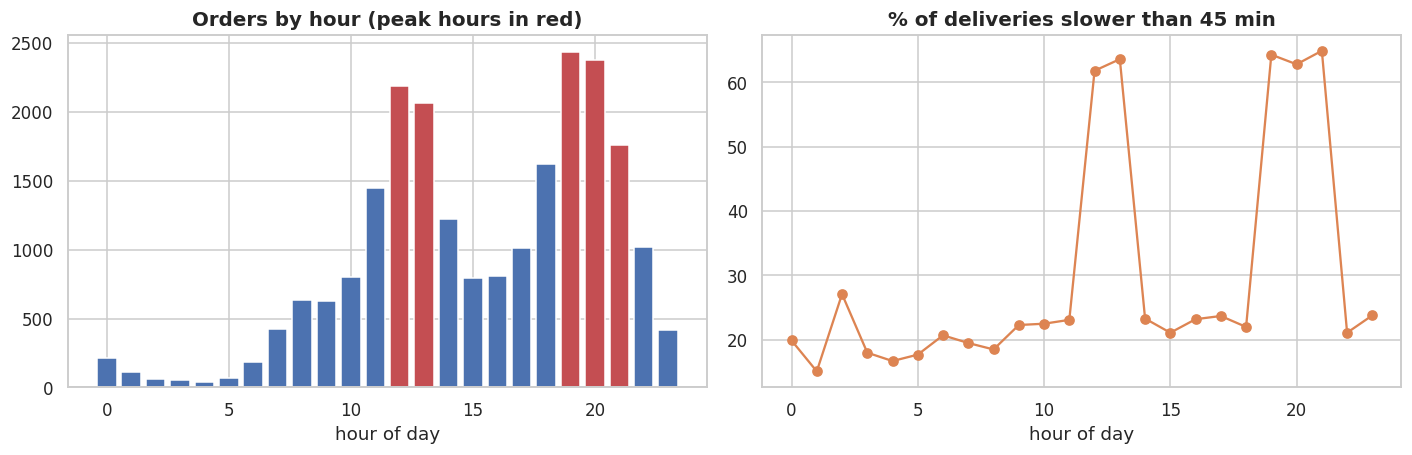

Peak hours (12-13h, 19-21h) = 48% of orders; avg delivery 47.9 min vs 41.0 min off-peak


In [4]:
hr = run("03_peak_hours_and_delivery_time")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].bar(hr.hour, hr.orders, color=["#c44e52" if h in (12, 13, 19, 20, 21) else "#4c72b0" for h in hr.hour]); ax[0].set_title("Orders by hour (peak hours in red)"); ax[0].set_xlabel("hour of day")
ax[1].plot(hr.hour, hr.pct_over_45min, marker="o", color="#dd8452"); ax[1].set_title("% of deliveries slower than 45 min"); ax[1].set_xlabel("hour of day")
plt.tight_layout(); plt.savefig(IMG + "02_peak_hours.png"); plt.show()
peak = hr[hr.hour.isin([12, 13, 19, 20, 21])]; off = hr[~hr.hour.isin([12, 13, 19, 20, 21])]
print(f"Peak hours (12-13h, 19-21h) = {peak.pct_of_orders.sum():.0f}% of orders; "
      f"avg delivery {np.average(peak.avg_delivery_min, weights=peak.orders):.1f} min vs {np.average(off.avg_delivery_min, weights=off.orders):.1f} min off-peak")

## 4. Delivery SLA by city (median and P90)
`sql/04_delivery_sla_by_city.sql` - SQLite has no `PERCENTILE`, so percentiles are built with `ROW_NUMBER()` and `COUNT() OVER`.

,city,delivered_orders,avg_min,median_min,p90_min,pct_within_40min
0,Bengaluru,4480,48.5,48.0,57.0,9.9
1,Mumbai,4876,46.7,46.0,55.0,16.9
2,Delhi,5228,42.7,42.0,51.0,38.9
3,Hyderabad,2728,42.5,42.0,51.0,39.0
4,Pune,2411,39.8,39.0,48.0,57.9
5,Meerut,801,36.7,36.0,45.0,74.4


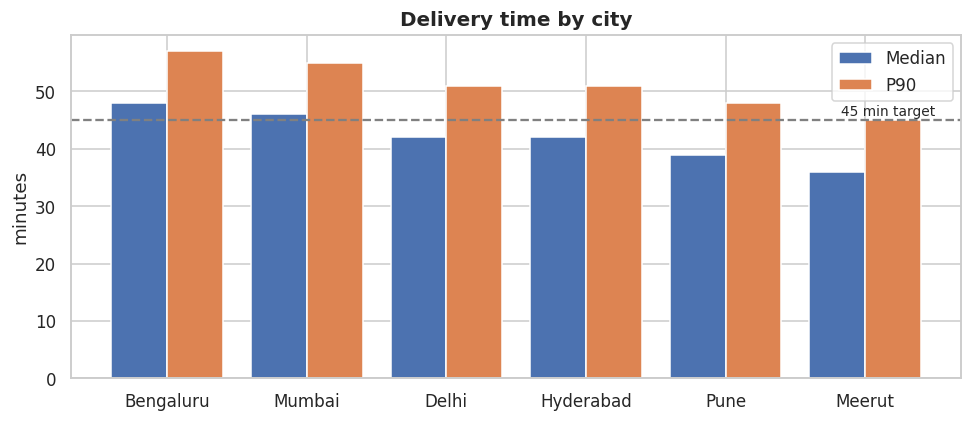

In [5]:
sla = run("04_delivery_sla_by_city"); display(sla)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(sla)); ax.bar(x - .2, sla.median_min, .4, label="Median"); ax.bar(x + .2, sla.p90_min, .4, label="P90")
ax.axhline(45, ls="--", c="grey"); ax.text(len(sla)-.5, 45.8, "45 min target", ha="right", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(sla.city); ax.set_ylabel("minutes"); ax.legend(); ax.set_title("Delivery time by city")
plt.tight_layout(); plt.savefig(IMG + "03_city_sla.png"); plt.show()

## 5. Retention: signup-cohort analysis
`sql/05_cohort_retention.sql` - multi-step CTEs, month arithmetic, `COUNT(DISTINCT ...)`. Each cell is the % of a signup month's customers who ordered N months later.

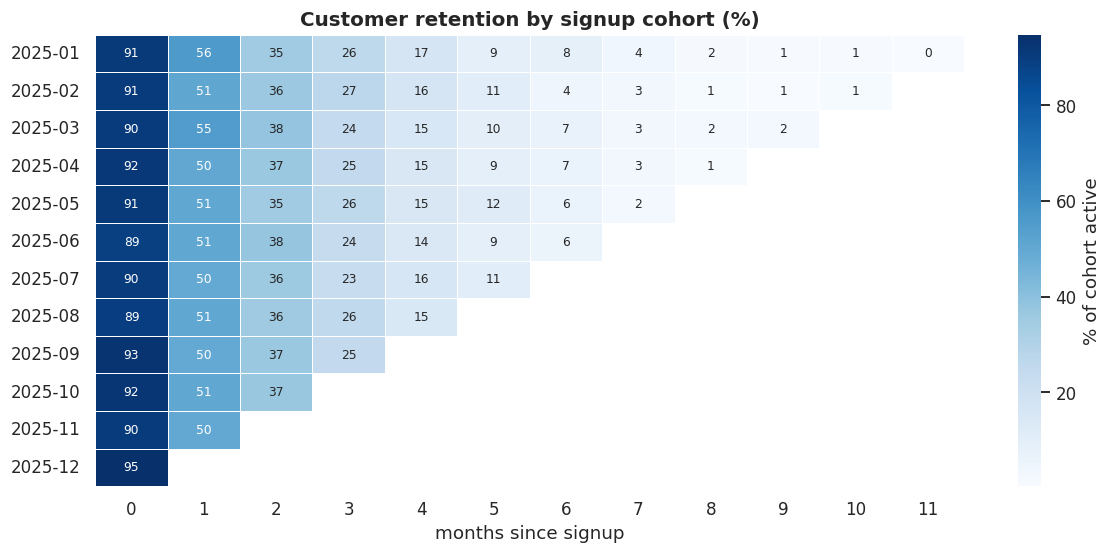

Weighted month-1 retention (cohorts Jan-Nov): 51%


In [6]:
ret = run("05_cohort_retention")
heat = ret.pivot(index="cohort_month", columns="month_number", values="retention_pct")
# mask months that have not happened yet for later cohorts (Dec data ends at month 11 for Jan cohort)
plt.figure(figsize=(11, 5.2)); sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of cohort active"}, linewidths=.5, annot_kws={"size": 8})
plt.gca().grid(False); plt.title("Customer retention by signup cohort (%)"); plt.xlabel("months since signup"); plt.ylabel("")
plt.tight_layout(); plt.savefig(IMG + "04_cohort_retention.png"); plt.show()
# size-weighted retention for months where every cohort is observable
ok = ret[ret.cohort_month <= "2025-11"]
m1 = ok[ok.month_number == 1].active_customers.sum() / ok.drop_duplicates("cohort_month").cohort_customers.sum()
print(f"Weighted month-1 retention (cohorts Jan-Nov): {m1:.0%}")

## 6. Acquisition channel quality
`sql/06_acquisition_channel_quality.sql` - cheap customers are not always good customers.

,acquisition_channel,customers,avg_orders,avg_ltv,repeat_rate_pct,never_delivered_pct
0,Referral,968,4.66,3108.0,74.7,2.2
1,Organic,2052,3.65,2426.0,68.2,2.4
2,Google Ads,926,3.36,2185.0,68.3,2.9
3,Paid Social,1578,2.69,1778.0,59.8,3.0
4,Influencer,476,2.47,1659.0,57.8,2.3


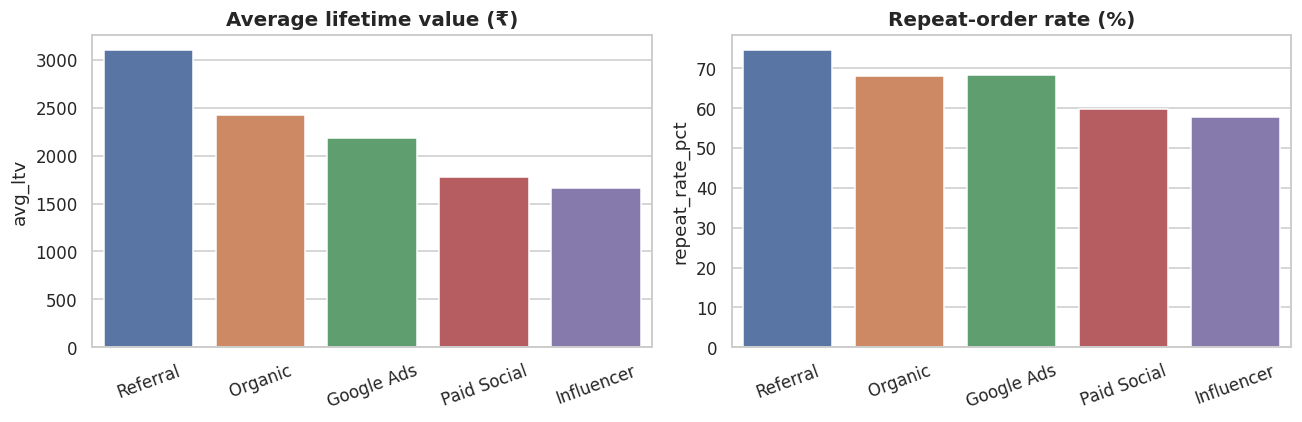

In [7]:
ch = run("06_acquisition_channel_quality"); display(ch)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=ch, x="acquisition_channel", y="avg_ltv", hue="acquisition_channel", legend=False, ax=ax[0]); ax[0].set_title("Average lifetime value (₹)"); ax[0].set_xlabel("")
sns.barplot(data=ch, x="acquisition_channel", y="repeat_rate_pct", hue="acquisition_channel", legend=False, ax=ax[1]); ax[1].set_title("Repeat-order rate (%)"); ax[1].set_xlabel("")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(IMG + "05_channel_quality.png"); plt.show()

## 7. Customer value concentration
`sql/07_customer_value_tiers.sql` - `NTILE(10)` deciles and cumulative revenue share with window sums.

,decile,customers,avg_orders,total_spend,pct_of_revenue,cumulative_pct
0,1,585,10.9,4526005.0,33.3,33.3
1,2,585,6.1,2521444.0,18.5,51.8
2,3,585,4.4,1801369.0,13.2,65.0
3,4,585,3.4,1373016.0,10.1,75.1
4,5,585,2.7,1061611.0,7.8,82.9
5,6,584,2.2,808579.0,5.9,88.9
6,7,584,1.7,609885.0,4.5,93.4
7,8,584,1.4,439134.0,3.2,96.6
8,9,584,1.2,295681.0,2.2,98.8
9,10,584,1.0,167334.0,1.2,100.0


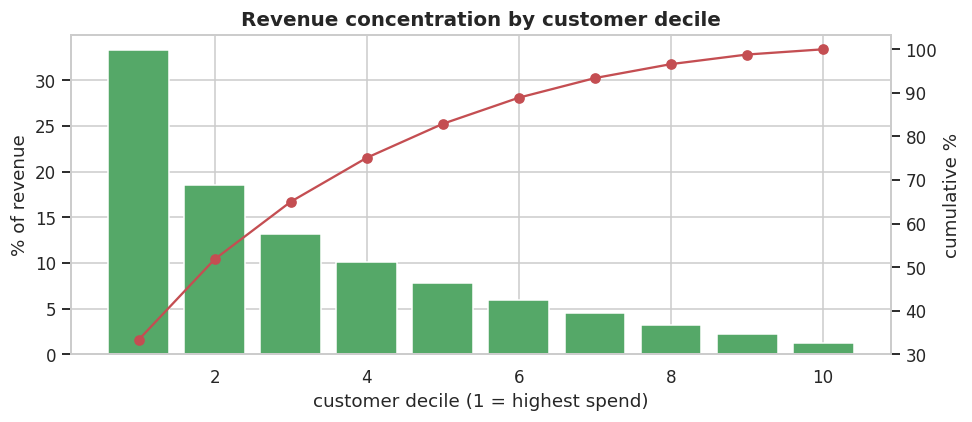

In [8]:
dec = run("07_customer_value_tiers"); display(dec)
fig, ax = plt.subplots(figsize=(9, 4)); ax.bar(dec.decile, dec.pct_of_revenue, color="#55a868"); ax.set_xlabel("customer decile (1 = highest spend)"); ax.set_ylabel("% of revenue")
ax2 = ax.twinx(); ax2.plot(dec.decile, dec.cumulative_pct, color="#c44e52", marker="o"); ax2.set_ylabel("cumulative %"); ax2.grid(False)
ax.set_title("Revenue concentration by customer decile"); plt.tight_layout(); plt.savefig(IMG + "06_value_deciles.png"); plt.show()

## 8. Discounts, cuisines and cloud kitchens

In [9]:
disc = run("08_discount_effectiveness"); display(disc)
cui = run("09_cuisine_performance"); display(cui)
ck = run("10_cloud_kitchen_vs_dine_in"); display(ck)

,discount_band,orders,avg_order_value,total_discount_given,discount_pct_of_gmv,cancel_rate_pct
0,0%,11186,697.3,0.0,0.0,7.5
1,1-10%,3138,694.4,217203.0,10.0,6.5
2,11-20%,4798,699.2,497309.0,14.8,6.5
3,21%+,3262,706.1,586504.0,25.5,7.2


,cuisine,restaurants,orders,revenue,revenue_share_pct,orders_per_restaurant,avg_rating
0,Chinese,30,2988,1952094.0,14.8,100.0,4.14
1,Pizza,24,1963,1814109.0,13.8,82.0,4.07
2,Healthy,20,2301,1770272.0,13.5,115.0,4.14
3,Burgers,29,2806,1735249.0,13.2,97.0,4.03
4,Biryani,21,1964,1627117.0,12.4,94.0,4.25
5,North Indian,19,1804,1332383.0,10.1,95.0,4.18
6,South Indian,27,2314,1118299.0,8.5,86.0,4.30
7,Street Food,25,2443,909471.0,6.9,98.0,4.12
8,Desserts,25,1941,892071.0,6.8,78.0,4.16


,kitchen_type,orders,avg_delivery_min,cancel_rate_pct,avg_order_value,avg_rating
0,Cloud kitchen,6532,40.7,6.0,721.2,4.15
1,Regular restaurant,15852,45.8,7.5,689.3,4.15


## 9. Findings (generated from the query results above)

In [10]:
cust_rank = ch.set_index("acquisition_channel")
best, worst = ch.iloc[0], ch.iloc[-1]
spread = disc.set_index("discount_band")
slow, fast = sla.iloc[0], sla.iloc[-1]
c, r = ck.set_index("kitchen_type").loc["Cloud kitchen"], ck.set_index("kitchen_type").loc["Regular restaurant"]
net_total = kpi.net_gmv.sum()
txt = f'''
| # | Finding | Evidence | Suggested action |
|---|---|---|---|
| 1 | **Strong growth, stable basket** | Net GMV went from ₹{kpi.net_gmv.iloc[0]/1e5:.1f} L (Jan) to ₹{kpi.net_gmv.iloc[-1]/1e5:.1f} L (Dec); AOV stayed ≈ ₹{kpi.aov.mean():.0f} | Growth is volume-driven; test basket-building (combos, add-ons) |
| 2 | **Peak hours hurt service** | Peak hours carry {peak.pct_of_orders.sum():.0f}% of orders and deliveries are ~{np.average(peak.avg_delivery_min, weights=peak.orders)-np.average(off.avg_delivery_min, weights=off.orders):.0f} min slower | Add rider incentives / surge capacity 12-14h and 19-22h |
| 3 | **City gap** | {slow.city} averages {slow.avg_min:.0f} min (P90 {slow.p90_min:.0f}) vs {fast.city} {fast.avg_min:.0f} min | Prioritise rider supply + restaurant clustering in {slow.city} |
| 4 | **Retention drops fast** | Only ~{m1:.0%} of a cohort orders again in month 1 | Trigger a 2nd-order offer in the first 7 days |
| 5 | **{best.acquisition_channel} beats {worst.acquisition_channel}** | LTV ₹{best.avg_ltv:,.0f} vs ₹{worst.avg_ltv:,.0f}; repeat rate {best.repeat_rate_pct:.0f}% vs {worst.repeat_rate_pct:.0f}% | Shift budget toward referrals; review {worst.acquisition_channel} CAC |
| 6 | **Top 10% customers = {dec.pct_of_revenue.iloc[0]:.0f}% of revenue** | Top decile averages {dec.avg_orders.iloc[0]:.0f} orders | VIP programme to protect the core |
| 7 | **Discounts do not lift basket size** | AOV ₹{spread.avg_order_value.iloc[0]:.0f} with no discount vs ₹{spread.avg_order_value.iloc[-1]:.0f} at 21%+; ₹{disc.total_discount_given.sum()/1e5:.1f} L given away | Replace blanket discounts with targeted, first-order offers |
| 8 | **Cloud kitchens are faster** | {c.avg_delivery_min:.0f} vs {r.avg_delivery_min:.0f} min and {c.cancel_rate_pct:.1f}% vs {r.cancel_rate_pct:.1f}% cancellations | Expand cloud-kitchen supply in slow cities |
'''
display(Markdown(txt))


| # | Finding | Evidence | Suggested action |
|---|---|---|---|
| 1 | **Strong growth, stable basket** | Net GMV went from ₹3.4 L (Jan) to ₹18.1 L (Dec); AOV stayed ≈ ₹700 | Growth is volume-driven; test basket-building (combos, add-ons) |
| 2 | **Peak hours hurt service** | Peak hours carry 48% of orders and deliveries are ~7 min slower | Add rider incentives / surge capacity 12-14h and 19-22h |
| 3 | **City gap** | Bengaluru averages 48 min (P90 57) vs Meerut 37 min | Prioritise rider supply + restaurant clustering in Bengaluru |
| 4 | **Retention drops fast** | Only ~51% of a cohort orders again in month 1 | Trigger a 2nd-order offer in the first 7 days |
| 5 | **Referral beats Influencer** | LTV ₹3,108 vs ₹1,659; repeat rate 75% vs 58% | Shift budget toward referrals; review Influencer CAC |
| 6 | **Top 10% customers = 33% of revenue** | Top decile averages 11 orders | VIP programme to protect the core |
| 7 | **Discounts do not lift basket size** | AOV ₹697 with no discount vs ₹706 at 21%+; ₹13.0 L given away | Replace blanket discounts with targeted, first-order offers |
| 8 | **Cloud kitchens are faster** | 41 vs 46 min and 6.0% vs 7.5% cancellations | Expand cloud-kitchen supply in slow cities |


**Limitations:** synthetic data; no cost / CAC data so profitability and channel ROI cannot be computed; the retention view only covers 2025.
Correlation in this data is not proof of causation - e.g. discounts and basket size would need an A/B test (see project 3).